In [ ]:
"""
Notebook is solving

dot{z}_1 = z_2
dot{z}_2 = - |z_1|

z_1(0) = 0
z_1(4) = -2
"""

import numpy
from scipy.integrate import solve_bvp
import matplotlib.pyplot as plt


def ode(t, x):
    """
    Implementing:
    dot{z}_1 = z_2
    dot{z}_2 = - |z_1|
    """
    x1 = x[0]
    x2 = x[1]
    return numpy.vstack((x2, - numpy.abs(x1)))


def boundary_conditions(x_start, x_end):
    """
    Boundary conditions have to be put into normal form.
    Implementing:
    z_1(0) = 0
    z_1(4) + 2 = 0
    """
    # We pick the index 0 because z_1 is used.
    return numpy.array([x_start[0], x_end[0] + 2])

In [2]:
steps = 100
t_mesh = numpy.linspace(0, 4, steps)
x_guess = numpy.zeros((2, len(t_mesh)))

solution = solve_bvp(ode, boundary_conditions, t_mesh, x_guess)
print(solution)

       message: The algorithm converged to the desired accuracy.
       success: True
        status: 0
             x: [ 0.000e+00  4.040e-02 ...  3.960e+00  4.000e+00]
           sol: <scipy.interpolate._interpolate.PPoly object at 0x0000017D218B5090>
             p: None
             y: [[ 0.000e+00  8.348e-02 ... -1.885e+00 -2.000e+00]
                 [ 2.067e+00  2.065e+00 ... -2.797e+00 -2.876e+00]]
            yp: [[ 2.067e+00  2.065e+00 ... -2.797e+00 -2.876e+00]
                 [-0.000e+00 -8.348e-02 ... -1.885e+00 -2.000e+00]]
 rms_residuals: [ 7.530e-07  6.961e-07 ...  4.136e-07  4.131e-07]
         niter: 3


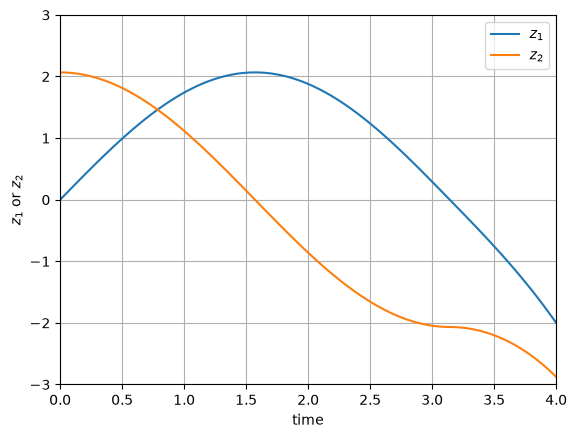

In [4]:
t_plot = numpy.linspace(0, 4, steps)
x_plot = solution.sol(t_plot)

plt.plot(t_plot, x_plot[0], label=r"$z_1$")
plt.plot(t_plot, x_plot[1], label=r"$z_2$")
plt.xlabel("time")
plt.ylabel(r"$z_1$ or $z_2$")
plt.xlim((0, 4))
plt.ylim((-3, 3))
plt.grid()
plt.legend()
plt.show()
